# 04 Evaluation

PLAN.md step 5, on held-out (test-match) predictions only. Logic is in `src/passmodel/evaluate.py`; `scripts/run_pipeline.py` writes the `results/step5_*` files this notebook reads.

In [1]:
import pandas as pd
from IPython.display import Image
from passmodel.load import REPO_ROOT

RESULTS = REPO_ROOT / "results"
read = lambda name, **kw: pd.read_csv(RESULTS / f"{name}.csv", **kw)

## Metrics per fold, with 95% bootstrap CIs
Resampling test passes 1,000 times. `delta_log_loss` = model minus logistic baseline on the same resample (negative = better than the baseline).

In [2]:
ci = read("step5_bootstrap_ci")
ci.pivot_table(index=["metric", "model"], columns="fold", values="estimate")

fold                                        1       2       3
metric         model                                         
brier          constant                0.1904  0.1507  0.1647
               logistic (pass length)  0.1887  0.1504  0.1639
               xgboost (all features)  0.1678  0.1327  0.1461
delta_log_loss constant                0.0046  0.0010  0.0018
               logistic (pass length)  0.0000  0.0000  0.0000
               xgboost (all features) -0.0463 -0.0604 -0.0552
log_loss       constant                0.5710  0.4800  0.5111
               logistic (pass length)  0.5664  0.4790  0.5093
               xgboost (all features)  0.5201  0.4186  0.4541
roc_auc        constant                0.5000  0.5000  0.5000
               logistic (pass length)  0.5718  0.5534  0.5542
               xgboost (all features)  0.7273  0.7481  0.7414

In [3]:
ci[ci["metric"] == "delta_log_loss"]

,model,fold,metric,estimate,ci_low,ci_high
3,constant,1,delta_log_loss,0.0046,-0.0002,0.0092
7,logistic (pass length),1,delta_log_loss,0.0000,0.0000,0.0000
11,xgboost (all features),1,delta_log_loss,-0.0463,-0.0763,-0.0176
15,constant,2,delta_log_loss,0.0010,-0.0035,0.0054
19,logistic (pass length),2,delta_log_loss,0.0000,0.0000,0.0000
23,xgboost (all features),2,delta_log_loss,-0.0604,-0.0830,-0.0377
27,constant,3,delta_log_loss,0.0018,-0.0033,0.0070
31,logistic (pass length),3,delta_log_loss,0.0000,0.0000,0.0000
35,xgboost (all features),3,delta_log_loss,-0.0552,-0.0781,-0.0344


## Calibration (all three held-out matches pooled, 10 equal-count bins)

In [4]:
read("step5_calibration")

,mean_predicted,observed_rate,n
0,0.4007,0.4806,335
1,0.6179,0.6527,334
2,0.7166,0.6946,334
3,0.7809,0.7582,335
4,0.8281,0.7964,334
5,0.8662,0.8503,334
6,0.8995,0.8627,335
7,0.9282,0.8832,334
8,0.9540,0.9431,334
9,0.9791,0.9642,335


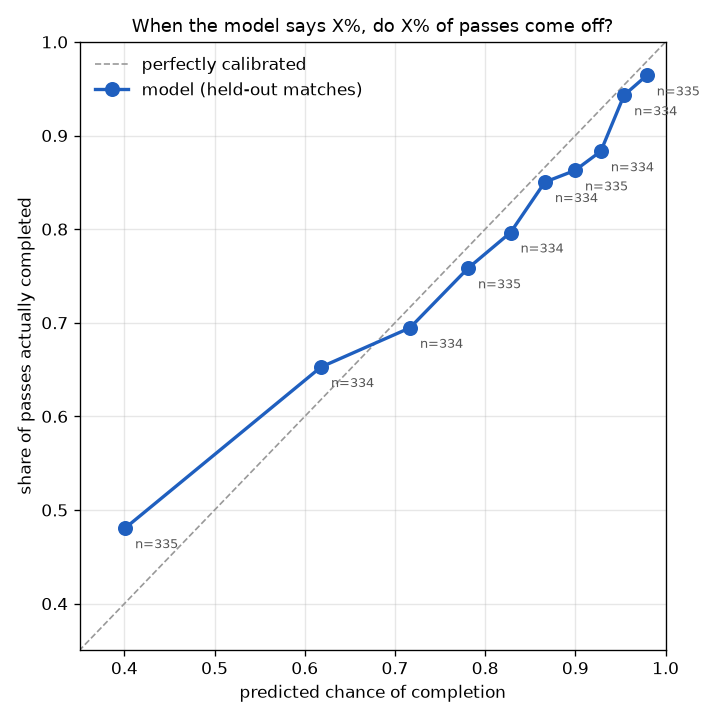

In [5]:
Image(RESULTS / "figures" / "calibration.png")

## SHAP (held-out passes, log-odds)

In [6]:
read("step5_shap_importance", index_col=0).head(10)

,mean_abs_shap
target_nearest_opp,0.3162
start_x,0.2895
passer_nearest_opp,0.2364
passer_speed,0.1832
lane_min_opp_dist,0.1650
start_y,0.1446
target_closing_speed,0.1397
passer_nearest_opp_speed,0.1297
target_confidence,0.1250
target_x,0.1234


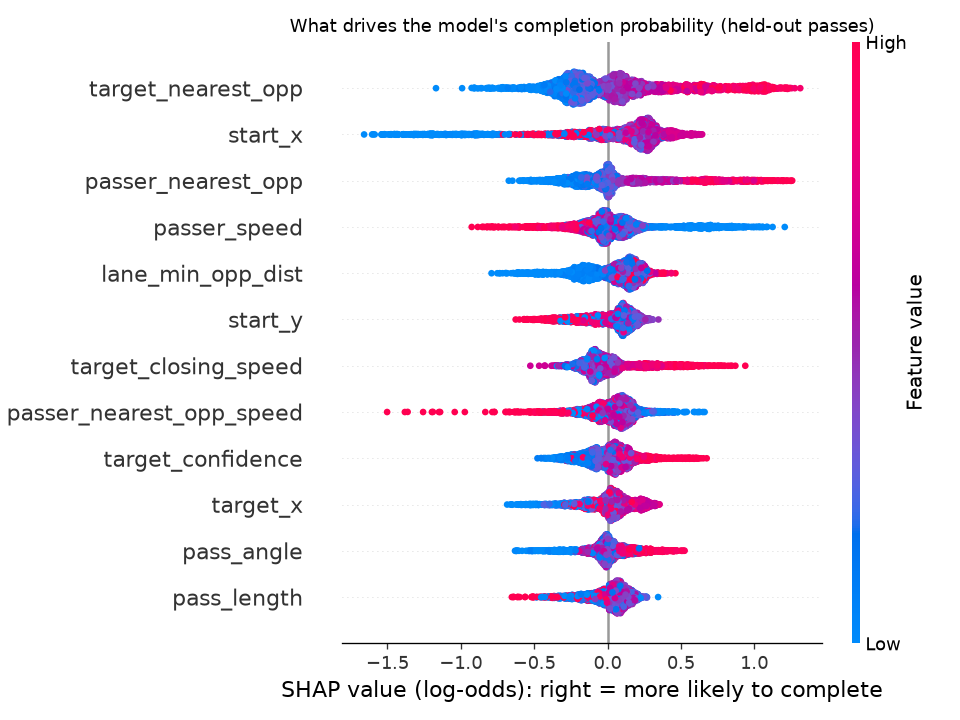

In [7]:
Image(RESULTS / "figures" / "shap_summary.png")

## Ablation: XGBoost refitted without each feature group
Positive delta = held-out log loss got worse without the group. Reported only; the headline model is not changed by this (that would be choosing features on the test matches).

In [8]:
read("step5_ablation", index_col=0)

,delta_log_loss_fold_1,delta_log_loss_fold_2,delta_log_loss_fold_3,delta_log_loss_fold_mean,folds_worse_without
model,,,,,
without location,0.0174,0.0257,0.0124,0.0185,3
without pressure,0.0011,0.0120,0.0096,0.0075,3
without event,0.0060,0.0067,0.0081,0.0069,3
without target,-0.0036,0.0067,0.0119,0.0050,2
without geometry,0.0048,0.0095,0.0009,0.0050,3
without speed,-0.0006,0.0057,0.0076,0.0042,2
without lane,-0.0028,0.0066,0.0038,0.0025,2


In [9]:
read("step5_ablation_ci").pivot(index="model", columns="fold", values=["estimate", "ci_low", "ci_high"])

estimate                  ci_low                 ci_high  \
fold                    1       2       3       1       2       3       1   
model                                                                       
without event      0.0060  0.0067  0.0081 -0.0026 -0.0014  0.0003  0.0148   
without geometry   0.0048  0.0096  0.0008 -0.0039  0.0022 -0.0065  0.0138   
without lane      -0.0027  0.0066  0.0037 -0.0127  0.0006 -0.0025  0.0074   
without location   0.0174  0.0258  0.0124  0.0012  0.0132 -0.0010  0.0338   
without pressure   0.0011  0.0120  0.0096 -0.0085  0.0054  0.0035  0.0113   
without speed     -0.0006  0.0058  0.0075 -0.0128 -0.0049 -0.0019  0.0112   
without target    -0.0036  0.0068  0.0119 -0.0154 -0.0021  0.0016  0.0076   

                                  
fold                   2       3  
model                             
without event     0.0148  0.0160  
without geometry  0.0167  0.0078  
without lane      0.0131  0.0096  
without location  0.0384  0.0267  
without pressure  0.0183  0.0165  
without speed     0.0155  0.0171  
without target    0.0158  0.0224